# Who the list misses

The decision is a fixed budget: the top 20% inside each module. Accuracy is the wrong summary. A missed at-risk student is a false negative, and the gap that matters is the difference in that rate across groups.

Groups: deprivation collapsed to low (0–30%), mid (30–70%) and high (70–100%), plus a Missing band that is mostly students outside England; declared disability; age band; gender. Missing deprivation is shown but kept out of the low/mid/high gap. A group needs at least 50 people and 20 at-risk students before it enters the gap. Smaller groups stay in the table and are drawn in grey.

The same within-module flags are checked against `fairlearn.MetricFrame` on the day-28 deprivation split. The two implementations have to agree.


In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))

from oulad.config import CACHE_VERSION, FIG_DIR, PROC_DIR, REPORT_DIR

from oulad.fairness import reports_for_frame

groups = pd.read_csv(REPORT_DIR / "fairness_groups.csv")
day28 = groups.loc[groups["cutoff"] == 28, ["attribute", "group", "n", "n_pos", "base_rate", "selection_rate", "fnr", "fpr", "in_gap", "fnr_gap"]]
day28.round(3)


,attribute,group,n,n_pos,base_rate,selection_rate,fnr,fpr,in_gap,fnr_gap
22,imd_group,high,4119,1579,0.383,0.140,0.713,0.049,True,0.131
23,imd_group,mid,6231,2704,0.434,0.192,0.654,0.074,True,0.131
24,imd_group,low,4768,2450,0.514,0.275,0.582,0.123,True,0.131
25,imd_group,Missing,611,181,0.296,0.097,0.762,0.037,False,0.131
26,disability,N,14239,6109,0.429,0.195,0.648,0.077,True,0.023
27,disability,Y,1490,805,0.540,0.242,0.625,0.085,True,0.023
28,age_band,55<=,118,42,0.356,0.093,0.857,0.066,True,0.230
29,age_band,0-35,10943,5018,0.459,0.217,0.628,0.086,True,0.230
30,age_band,35-55,4668,1854,0.397,0.162,0.687,0.062,True,0.230
31,gender,M,9061,4163,0.459,0.210,0.618,0.063,True,0.067


In [2]:
scores = pd.read_parquet(PROC_DIR / "scores" / CACHE_VERSION / "temporal_lgbm_c28.parquet")
recomputed = reports_for_frame(scores)
merged = day28.merge(
    recomputed[["attribute", "group", "fnr"]],
    on=["attribute", "group"],
    suffixes=("_saved", "_live"),
)
assert (merged["fnr_saved"] - merged["fnr_live"]).abs().max() < 1e-9
print("day-28 false-negative rates match the saved table")
gaps = groups.groupby(["cutoff", "attribute"])["fnr_gap"].first().unstack("attribute")
gaps.round(3)


day-28 false-negative rates match the saved table


attribute,age_band,disability,gender,imd_group
cutoff,,,,
0,0.187,0.061,0.037,0.284
14,0.173,0.053,0.022,0.187
28,0.230,0.023,0.067,0.131
56,0.146,0.028,0.058,0.126
84,0.088,0.030,0.057,0.105


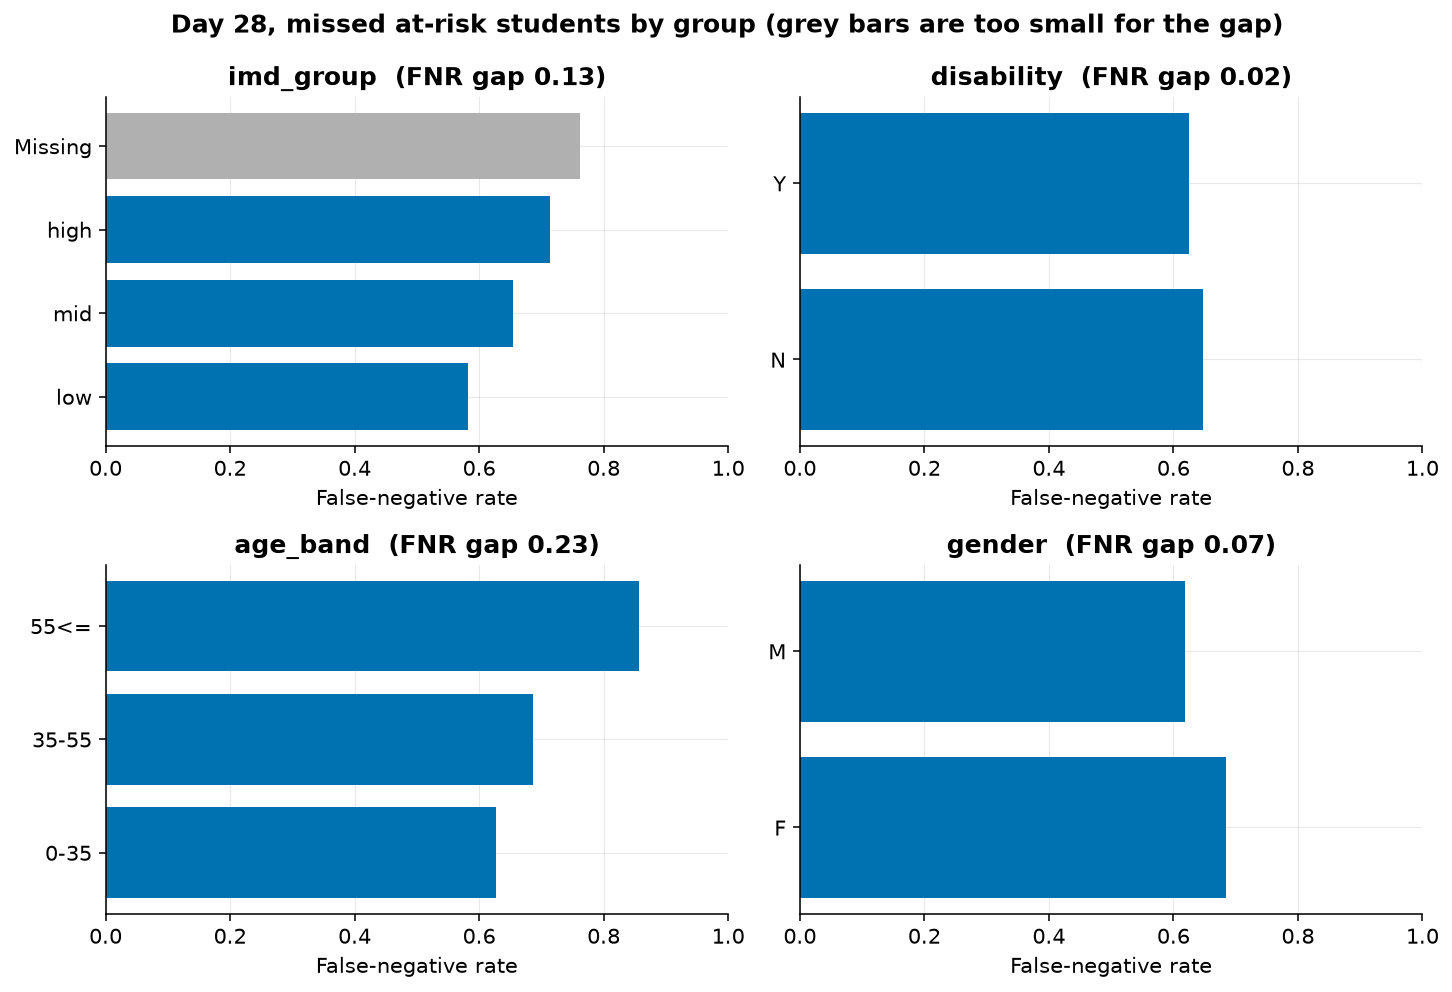

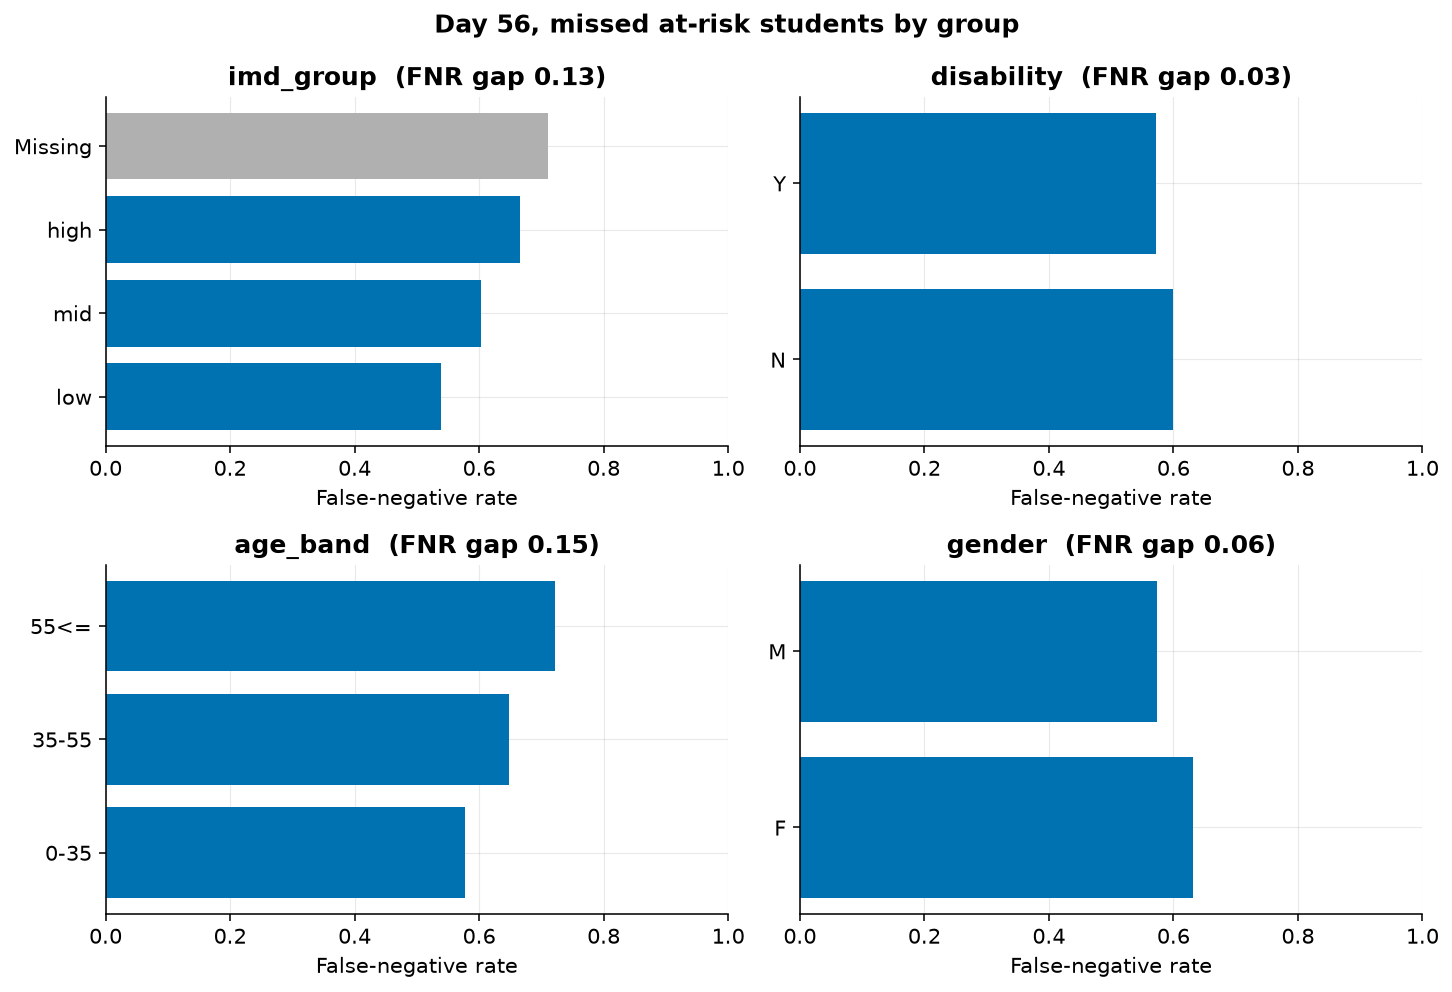

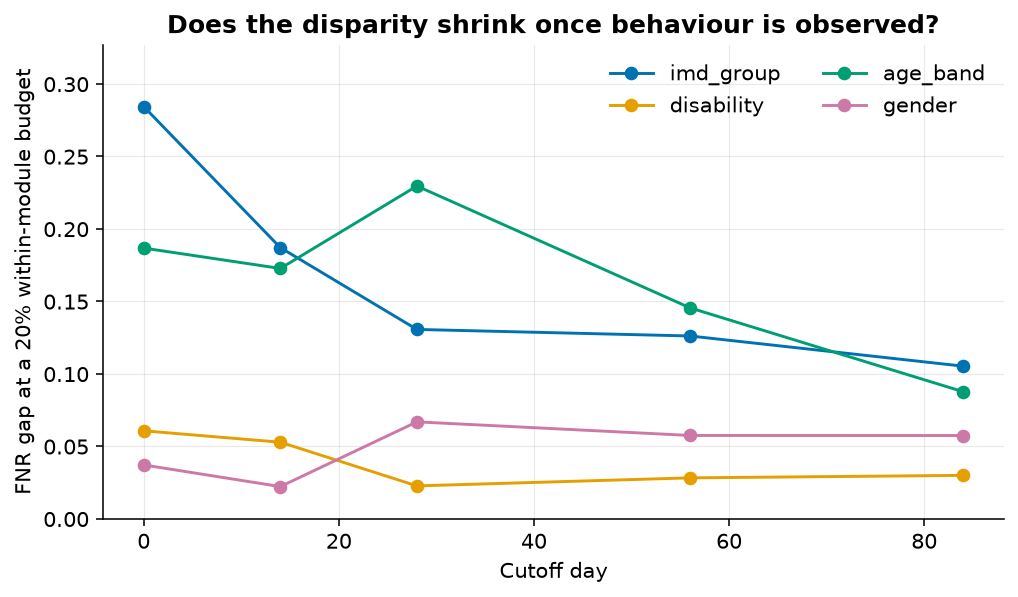

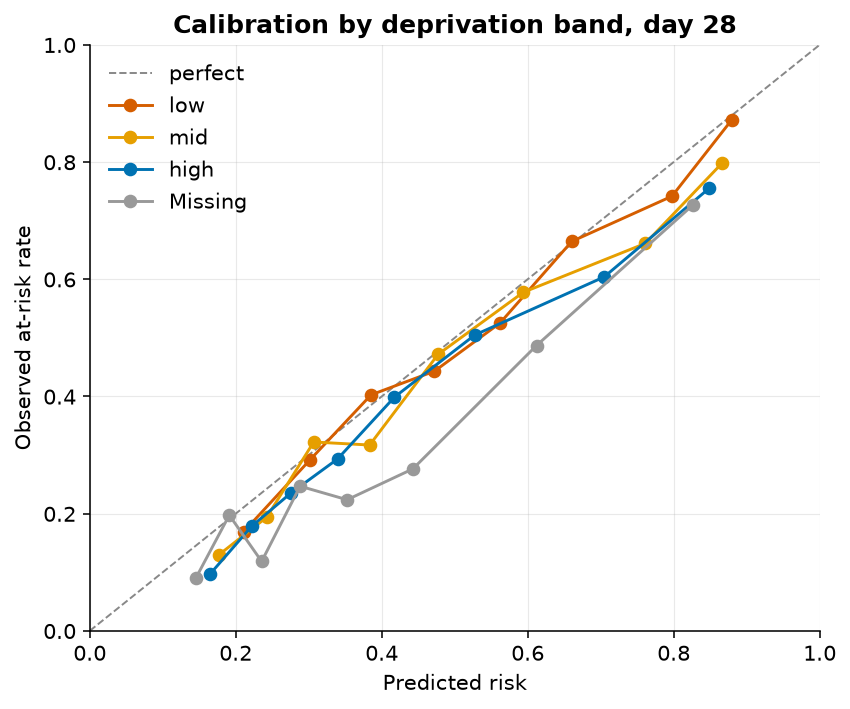

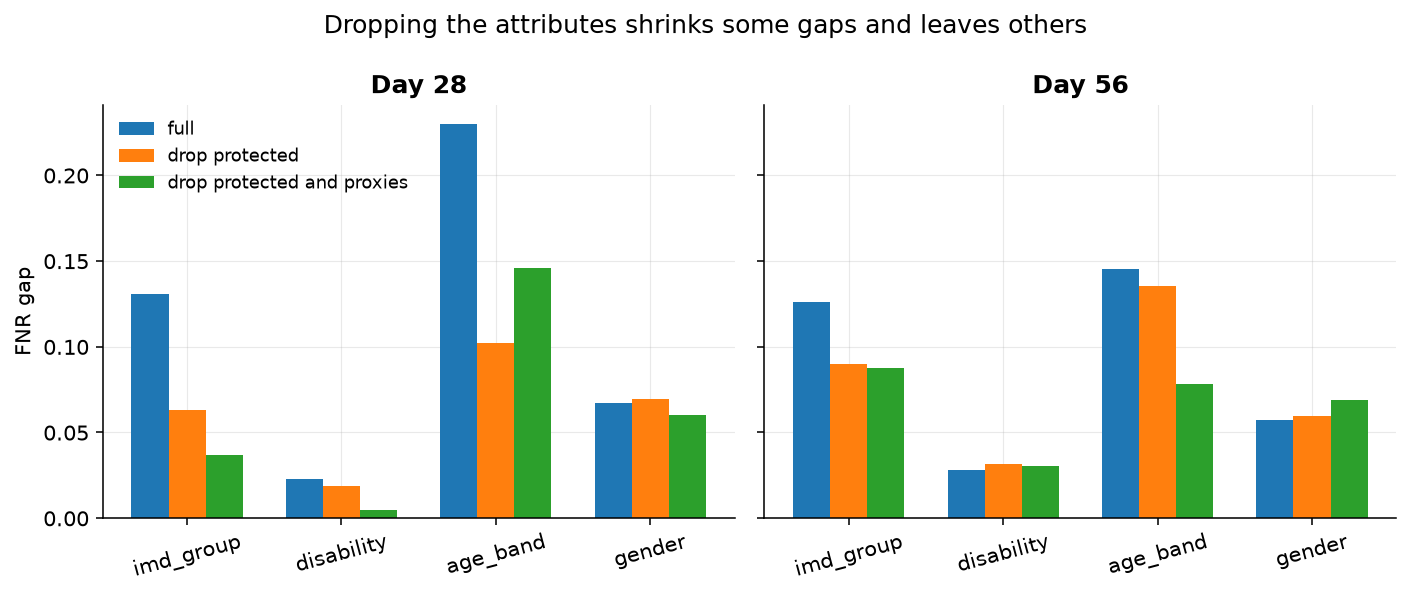

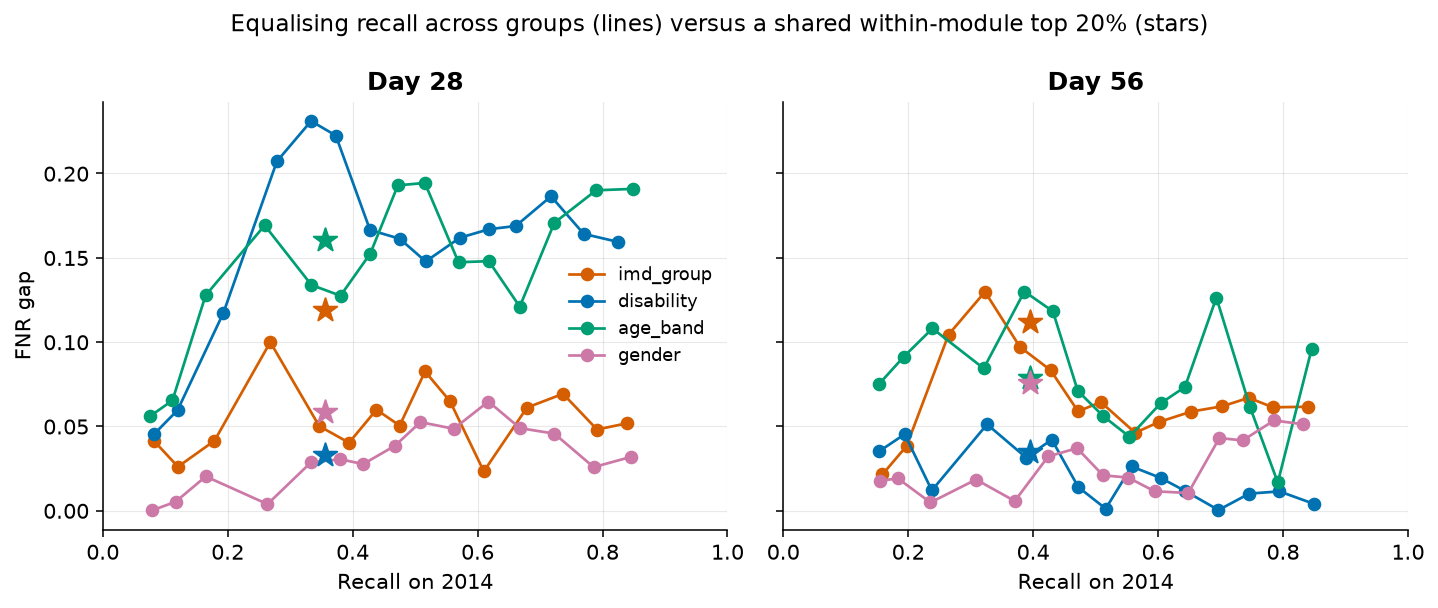

In [3]:
for name in (
    "fairness_fnr_day28",
    "fairness_fnr_day56",
    "fnr_gap_vs_cutoff",
    "calibration_imd_day28",
    "ablation_fnr_gap",
    "mitigation_tradeoff",
):
    display(Image(filename=str(FIG_DIR / f"{name}.png")))


## Taking the attributes out

The ablation refits the temporal model at day 28 and day 56 three times: with the protected fields, without them, and without them plus region and prior education. Engagement and assessment history stay in. If the false-negative gap barely moves, the model is not "using gender" in the simple sense. It is using study behaviour that differs across groups, and a shared threshold then misses different fractions of the at-risk students.

Day 0 is the early end of the same question. Most of that model's gain is clicks from before the start date, not the protected attributes themselves. It is still the wrong list to send a tutor: nobody has been taught yet, and the deprivation gap in missed at-risk students is largest there.


In [4]:
ablation = pd.read_csv(REPORT_DIR / "ablation.csv")
ablation.pivot_table(index=["cutoff", "attribute"], columns="variant", values="fnr_gap").round(3)


variant            drop protected  drop protected and proxies   full
cutoff attribute                                                    
28     age_band             0.102                       0.146  0.230
       disability           0.018                       0.005  0.023
       gender               0.069                       0.060  0.067
       imd_group            0.063                       0.037  0.131
56     age_band             0.135                       0.078  0.146
       disability           0.031                       0.030  0.028
       gender               0.060                       0.069  0.058
       imd_group            0.090                       0.087  0.126

## Equalising recall

The mitigation does not retrain the booster. A model is fit on 75% of the 2013 rows. On the other 25% it picks, for each group, the score cutoff that flags about the same fraction of at-risk students. Those cutoffs are applied to 2014. Sweeping the target recall traces the gap against overall recall. The stars are the unmitigated rule on that same model: each module's top 20%.

This is an illustration of the tradeoff, not a policy. Thresholds chosen on a few hundred positives in a small group are noisy, and a group with too few validation positives falls back to the overall cutoff. Nothing here was tuned on 2014.


In [5]:
import json
curves = pd.read_csv(REPORT_DIR / "mitigation.csv")
chosen = curves.loc[curves["chosen"], ["cutoff", "attribute", "target_recall", "test_recall", "selection_rate", "fnr_gap", "n_fallback_groups"]]
baselines = pd.DataFrame(json.loads((REPORT_DIR / "results.json").read_text())["mitigation_baselines"])
print("Unmitigated within-module top 20% on the threshold model")
display(baselines.round(3))
print("Chosen point: smallest FNR gap among selection rates between 15% and 25%")
chosen.round(3)


Unmitigated within-module top 20% on the threshold model


,attribute,test_recall,selection_rate,fnr_gap,cutoff
0,imd_group,0.356,0.2,0.119,28
1,disability,0.356,0.2,0.033,28
2,age_band,0.356,0.2,0.160,28
3,gender,0.356,0.2,0.058,28
4,imd_group,0.395,0.2,0.112,56
5,disability,0.395,0.2,0.035,56
6,age_band,0.395,0.2,0.079,56
7,gender,0.395,0.2,0.076,56


Chosen point: smallest FNR gap among selection rates between 15% and 25%


,cutoff,attribute,target_recall,test_recall,selection_rate,fnr_gap,n_fallback_groups
5,28,imd_group,0.40,0.394,0.232,0.040,0
20,28,disability,0.40,0.373,0.219,0.223,0
35,28,age_band,0.40,0.381,0.220,0.127,1
51,28,gender,0.45,0.417,0.247,0.028,0
65,56,imd_group,0.40,0.428,0.234,0.083,0
79,56,disability,0.35,0.389,0.206,0.031,0
93,56,age_band,0.30,0.321,0.163,0.084,1
109,56,gender,0.35,0.371,0.199,0.006,0


## Limits

Exam scores are missing for most students, so the label is the final result, not a mark. Withdrawn and Fail are different events: one stops early, the other stays and does not pass. A single at-risk label is what a tutor acts on, and it hides that difference.

The click vocabulary is this university's VLE. A model that transfers across these seven modules can still fail on a different institution. The threshold adjustment is not a deployed intervention, and it was not tested as one. Deprivation is a property of the postcode area, not of the person, and it is missing for students outside the English index.
